# Exercise 9 – Metropolis sampling of rugged potentials

**Week 2 · Monte Carlo sampling**

The Metropolis algorithm works for any potential. Here we try a staircase
potential and a potential with two Gaussian wells. For the staircase the
random walk has to climb the steps one at a time, while uniform proposals
can jump directly between wells.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.montecarlo import boltzmann_pdf, metropolis, thermal_average
from comphy.plotting import annotate, setup_axes

rng = np.random.default_rng(0)

STEPS = np.array([0, -1, -2, -3, -2, -1, -2, -1, 0])     # values on [0,1), [1,2), ...


def staircase(x):
    x = np.asarray(x, dtype=float)
    idx = np.clip(np.floor(x).astype(int), -1, len(STEPS))
    out = np.zeros_like(x)
    inside = (idx >= 0) & (idx < len(STEPS))
    out[inside] = STEPS[idx[inside]]
    return out


def two_wells(x):
    x = np.asarray(x, dtype=float)
    return -0.5 * np.exp(-((x - 4) ** 2) / 4) - np.exp(-((x - 0.5) ** 2))


def sample_and_plot(V, kT, lims, x0, proposal, sizes, ylim, title, bins=40):
    xs = np.linspace(*lims, 1000)
    pdf = boltzmann_pdf(V, kT, lims)
    exact = thermal_average(V, kT, lims)
    fig, axes = plt.subplots(1, len(sizes), figsize=(4.5 * len(sizes), 4), sharey=True)
    for ax, n in zip(axes, sizes):
        sample, acc = metropolis(V, kT, x0=x0, n_steps=n, rng=rng, **proposal)
        ax.hist(sample, bins=bins, range=lims, density=True, color="C0", alpha=0.6)
        ax.plot(xs, V(xs), color="C0")
        ax.plot(xs, pdf(xs), color="C1")
        annotate(ax, f"N = {n}, acceptance {acc:.0%}\n$\\langle V\\rangle$ = {V(sample).mean():.3f} "
                     f"(exact {exact:.3f})", fontsize=8)
        setup_axes(ax, xlim=lims, ylim=ylim, ylabel=None)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## Staircase potential, $k_BT = 0.75$

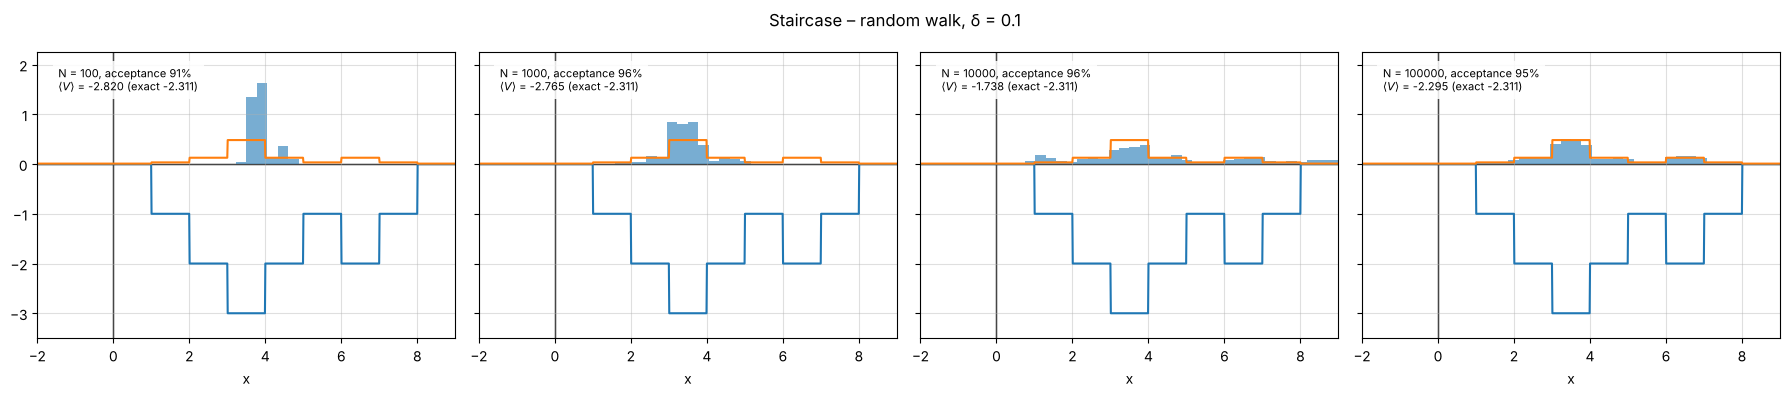

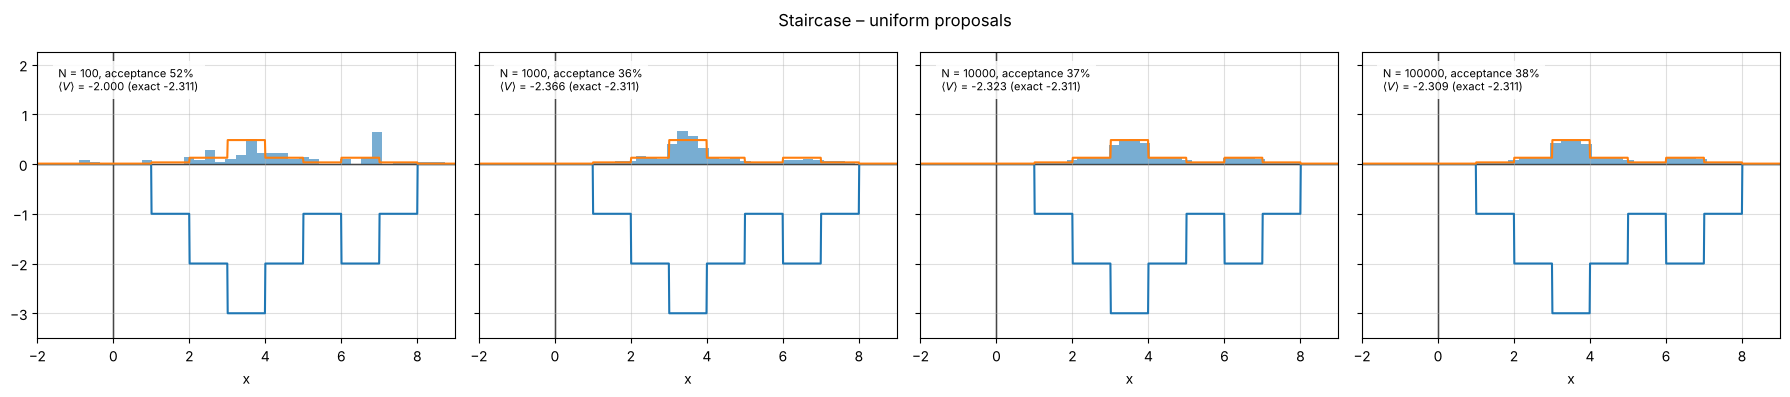

In [2]:
sizes = [100, 1_000, 10_000, 100_000]
sample_and_plot(staircase, 0.75, (-2, 9), 4.5, dict(step=0.1), sizes, (-3.5, 2.25),
                "Staircase – random walk, δ = 0.1")
sample_and_plot(staircase, 0.75, (-2, 9), 4.5, dict(lims=(-2, 9)), sizes, (-3.5, 2.25),
                "Staircase – uniform proposals")

## Two Gaussian wells, $k_BT = 0.15$

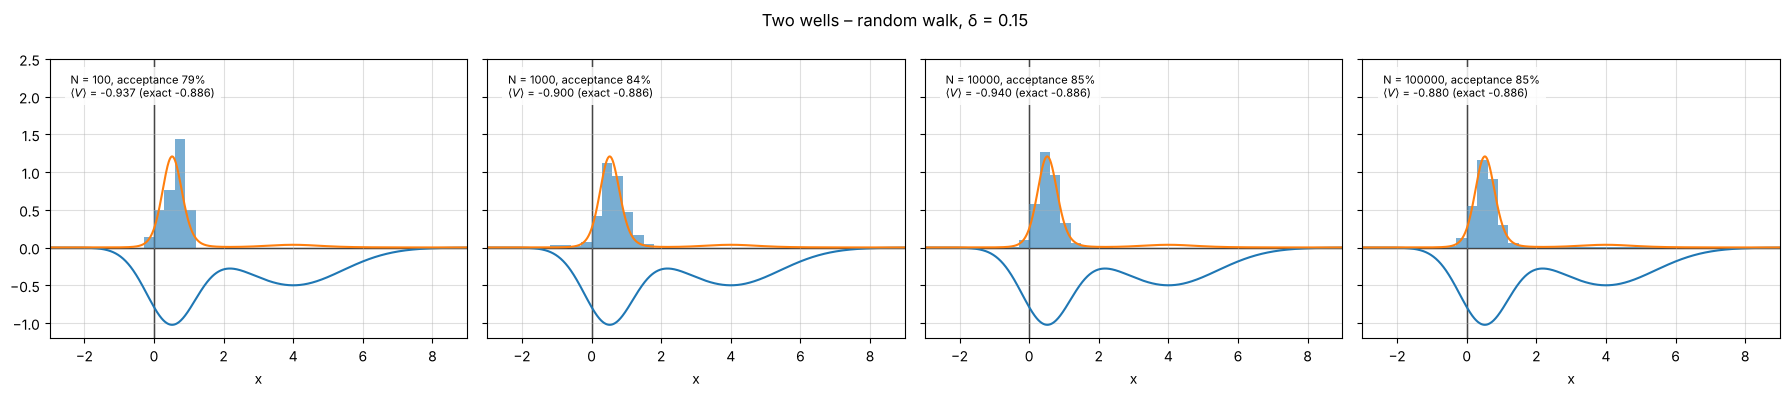

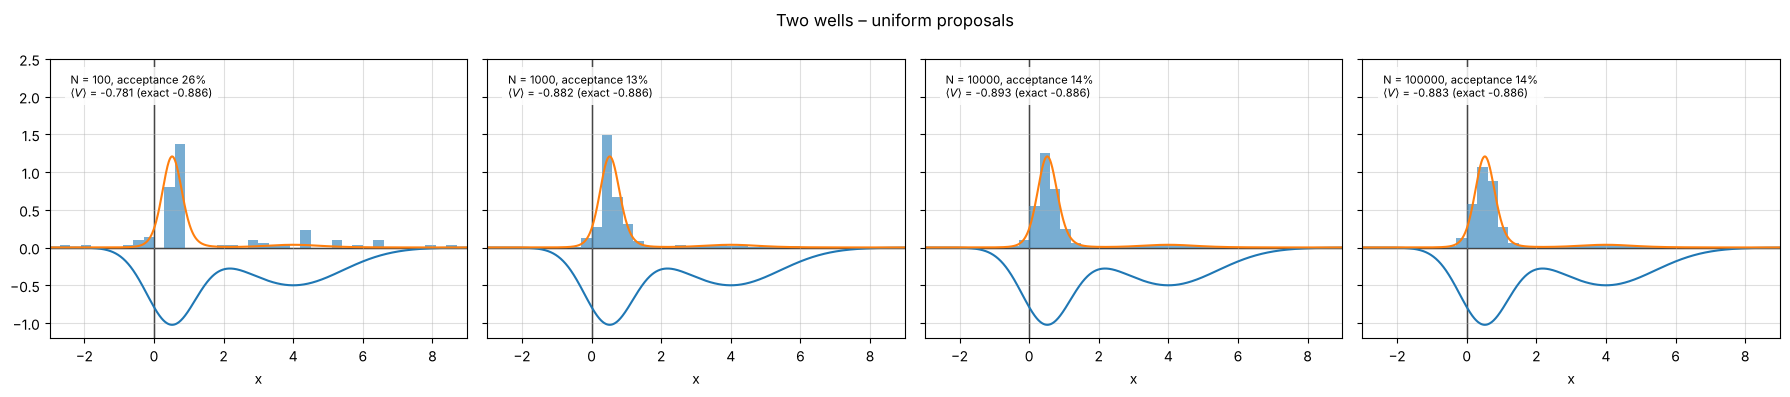

In [3]:
sample_and_plot(two_wells, 0.15, (-3, 9), 0.5, dict(step=0.15), sizes, (-1.2, 2.5),
                "Two wells – random walk, δ = 0.15")
sample_and_plot(two_wells, 0.15, (-3, 9), 0.5, dict(lims=(-3, 9)), sizes, (-1.2, 2.5),
                "Two wells – uniform proposals")

On the staircase, the small-step random walk has to diffuse across the
steps: its estimate of $\langle V\rangle$ is still far off after 10 000 steps
and only matches the exact value at 100 000. Uniform proposals jump anywhere
in one move and are already accurate after about 1000 steps, despite
accepting only ~37 % of the moves.

For the two wells at this low temperature almost all the probability sits in
the deep well, so both methods do well; the shallow well only becomes
important at higher temperature (exercise 10).